# JADES conditional flow

Train the same MLP + conditional NSF as `flow_method/flow_sed_jades.ipynb`, using Lightning and YAML.
Choose **z_1_3.yaml** for $1 < z_{\rm spec} \le 3$ or **full.yaml** for no redshift-range cut.
Both keep the current notebook's 50/25/25 train/validation/test split and train on JADES p50 labels.
The five targets are log10(1+z), log mass, log SFR100, log Zgas and log10(A_V / mag).


In [ ]:
import os, sys, re, shutil
from pathlib import Path
import numpy as np
import torch
import yaml
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "encoder_fusion/model/fusion.py").is_file())
FLOW_DIR = ROOT / "flow"
os.chdir(FLOW_DIR)
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "neurips"))
from flow.model.flow import Flow
from flow.data.datamodule_jades import JADESDataModule
from plotstyle import C_IMAGE, C_SPECTRUM, C_RED_BRIGHT, C_ORIG, use_style, style_axes, fs

CONFIG, rerun = Path("full.yaml"), True
#CONFIG, rerun = Path("z_1_3.yaml"), False

SEEDS = [0,1,2,3,42]           # use [0] for one flow
N_POST = 30000
cfg = yaml.safe_load(CONFIG.read_text())
base_name = cfg["trainer"]["logger"]["init_args"]["name"]
use_style(1.2)


## 1. Train from the notebook

The `!` command uses this notebook's Python environment. Each seed gets its own output directory;
the data split remains fixed by `data.split_seed`. Set `SEEDS = [0]` to train one flow.
`flow.py` contains the LightningCLI entry point; there is no separate trainer script.


In [ ]:
if rerun:
    save_dir = Path(cfg["trainer"]["logger"]["init_args"]["save_dir"])
    for seed in SEEDS:
        run_name = f"{base_name}_seed{seed}"
        # Delete all earlier runs of this seed, then train from scratch.
        if (save_dir / run_name).exists():
            print(f"Deleting {save_dir / run_name}")
            shutil.rmtree(save_dir / run_name)
        !{sys.executable} model/flow.py fit --config {CONFIG} --seed_everything={seed} --trainer.logger.init_args.name={run_name}


## 2. Load the best checkpoints and sample the test galaxies

The DataModule recomputes the frozen CLIP latents in batches; it does not train the fusion model.
The same data preparation is used for training and analysis. Labels and sample dimensions are aligned
with `data.rows`, `data.dja_ids` and `data.jades_ids`.


In [39]:
models, checkpoints = [], []
log_root = Path(cfg["trainer"]["logger"]["init_args"]["save_dir"])
for seed in SEEDS:
    versions = list((log_root / f"{base_name}_seed{seed}").glob("version_*"))
    latest = max(versions, key=lambda p: int(p.name.split("_")[-1]))
    paths = list((latest / "checkpoints").glob("*.ckpt"))
    checkpoints.append(paths[0])
    models.append(Flow.load_from_checkpoint(paths[0], map_location="cpu").eval())
print("Best checkpoints:", *checkpoints, sep="\n")

# Use the saved data settings, including the exact fusion checkpoint used in training.
data_config = dict(models[0].hparams.data_config)
data = JADESDataModule(**data_config)
data.setup("fit")
te = data.te
X_test = data.X[te]
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# Draw from the equal-weight mixture; the total is exactly N_POST.
n_per_flow = np.random.multinomial(N_POST, np.full(len(models), 1 / len(models)))
post_model = torch.cat([m.to(DEVICE).sample(X_test, n=int(n))
                        for m, n in zip(models, n_per_flow) if n], dim=0).numpy()
print("Posterior:", post_model.shape)


Best checkpoints:
outputs/flow_jades_full_seed0/version_0/checkpoints/epoch=16-val_nll=3.2323.ckpt
outputs/flow_jades_full_seed1/version_0/checkpoints/epoch=11-val_nll=3.1788.ckpt
outputs/flow_jades_full_seed2/version_0/checkpoints/epoch=15-val_nll=3.1776.ckpt
outputs/flow_jades_full_seed3/version_0/checkpoints/epoch=11-val_nll=3.1120.ckpt
outputs/flow_jades_full_seed42/version_1/checkpoints/epoch=16-val_nll=3.2234.ckpt
Converting flux from f_nu (uJy) to f_lambda (∝ f_nu / λ²) (use_jansky=True to disable this conversion)
grade in (1, 2, 3) filtering: 26486/42196 samples kept
valid_pix_frac > 0.5 filtering: 25025/42196 samples kept
LowResDataset: 25025 spectra, 56 pixels (1.004–1.991 µm)
Frozen fusion: /nexus/posix0/MIA-astro-env/ivemo/yacheng/ssl_outthere/encoder_fusion/outputs/fusion_dja_image_attn_spectrum_attn/version_2/checkpoints/epoch=39-R10=0.158-val_loss=4.7346.ckpt (cuda)
Flow data: 2645 spectra -> 2266 unique JADES galaxies; train 1133 / val 566 / test 567
Posterior: (30000, 

In [40]:
# Samples already have standardization undone by Flow.sample().
# These are still model-label coordinates; convert log10(1+z) to z for plots only.
post = post_model.copy()
yt, yt16, yt84 = (a[te].copy() for a in (data.Y, data.Y16, data.Y84))
names = list(data.hparams.target_columns)
plot_labels = {
    "log1pz": r"$z$", "logmass": r"$\log M_\star$",
    "logsfr100": r"$\log \mathrm{SFR}_{100}$", "gas_logz": r"$\log Z_{\rm gas}/Z_\odot$",
    "av": r"$\log_{10}(A_V/\mathrm{mag})$",
}
LABELS = [plot_labels.get(name, name) for name in names]
D = len(names)
if "log1pz" in names:
    z_index = names.index("log1pz")
    for a in (post[..., z_index], yt[:, z_index], yt16[:, z_index], yt84[:, z_index]):
        a[:] = 10 ** a - 1
lo16, med, hi84 = np.percentile(post, [16, 50, 84], axis=0)


def nmad(e):
    return 1.4826 * np.median(np.abs(e - np.median(e)))


def err(p, t, d):
    return (p - t) / (1 + t) if names[d] == "log1pz" else p - t


## 3. Posterior median vs catalog

Flow 16–84% intervals are vertical; catalog 16–84% intervals are horizontal.


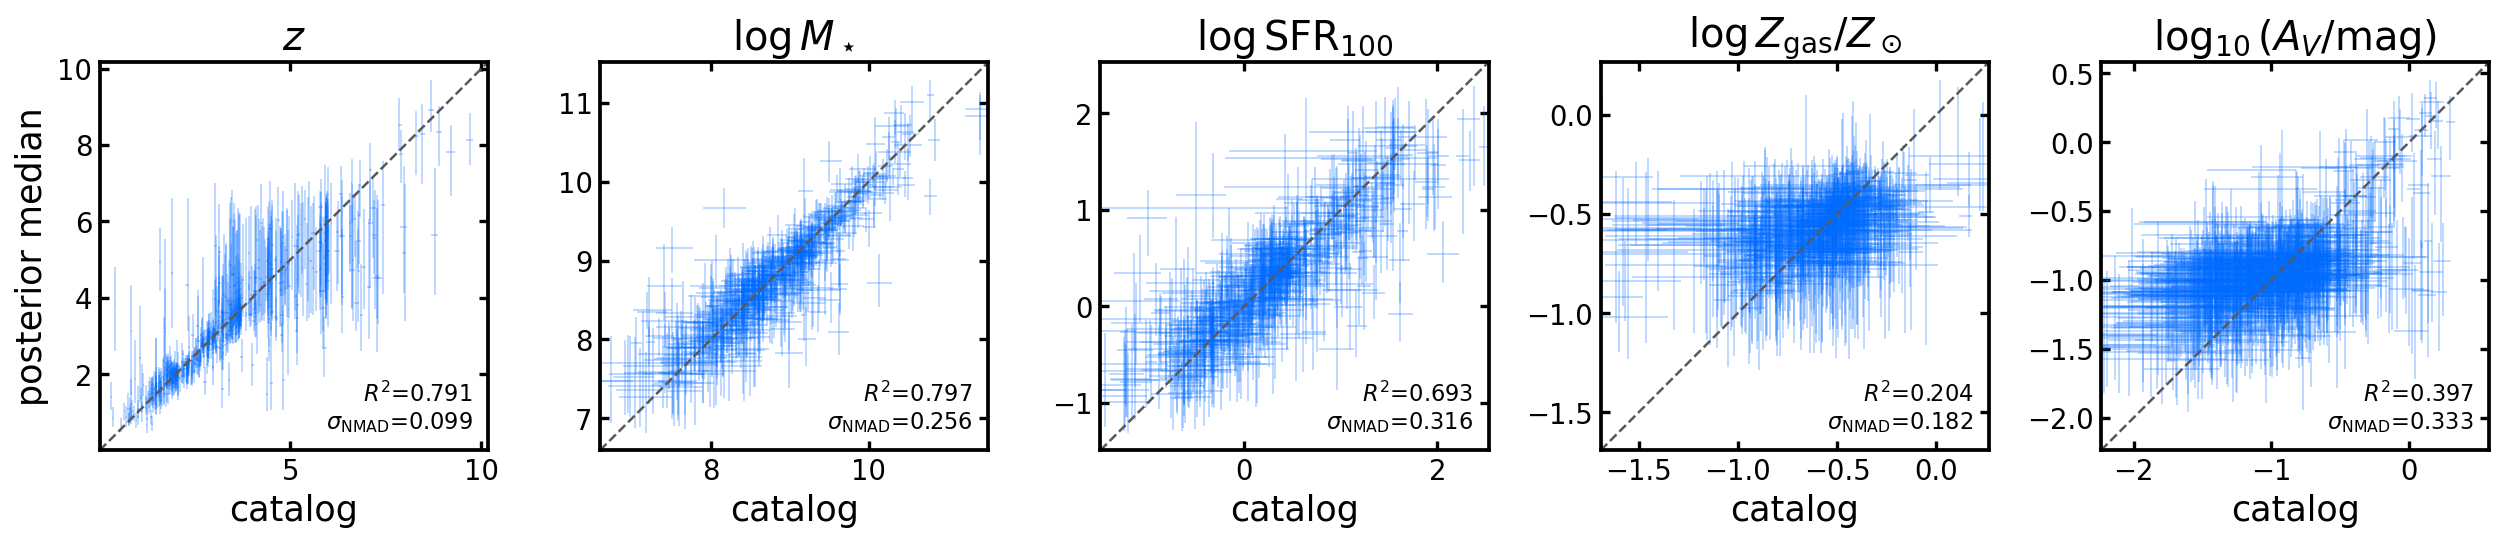

In [41]:
#show = np.random.default_rng(data.hparams.split_seed).choice(len(te), min(200, len(te)), replace=False)
# or just show every test galaxy
show = np.arange(len(te))

fig, axes = plt.subplots(1, D, figsize=(3.4 * D, 3.7))
for d, ax in enumerate(axes):
    t, p = yt[:, d], med[:, d]
    lo = min(np.percentile(t, 0.5), lo16[show, d].min())
    hi = max(np.percentile(t, 99.5), hi84[show, d].max())
    lo, hi = lo - 0.05 * (hi - lo), hi + 0.05 * (hi - lo)
    #ax.scatter(t, p, s=5, alpha=0.25, color=C_IMAGE, edgecolors="none", rasterized=True)
    ax.errorbar(t[show], p[show], yerr=[p[show] - lo16[show, d], hi84[show, d] - p[show]],
                xerr=[t[show] - yt16[show, d], yt84[show, d] - t[show]],
                fmt="none", ecolor=C_IMAGE, alpha=0.3, lw=0.8)
    ax.plot([lo, hi], [lo, hi], "--", color="0.35", lw=1.2)
    ax.text(0.96, 0.04, rf"$R^2$={r2_score(t, p):.3f}" + "\n" + rf"$\sigma_{{\rm NMAD}}$={nmad(err(p, t, d)):.3f}",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=fs(9))
    ax.set(xlim=(lo, hi), ylim=(lo, hi), xlabel="catalog", title=LABELS[d])
    ax.set_box_aspect(1)
    style_axes(ax)
axes[0].set_ylabel("posterior median")
fig.tight_layout()
plt.show()

## 4. PIT and central-interval coverage

For each target, PIT is the fraction of marginal samples below the held-out catalog p50.
A calibrated conditional label distribution has approximately uniform PIT. Each parameter is tested
separately; these checks do not by themselves validate all five-dimensional correlations.

A Beta($\alpha$, $\beta$) maximum-likelihood fit (red curve) summarizes each PIT histogram, with
1$\sigma$ errors from the Fisher information. $\alpha=\beta=1$ is uniform; $\alpha=\beta>1$ (hump) means the
posterior is too wide; $\alpha=\beta<1$ (U shape) means it is too narrow; $\alpha>\beta$ (PIT piled toward 1)
means the posterior sits below the catalog value, and $\alpha<\beta$ means it sits above.

log1pz       cov68=0.721  cov95=0.961
logmass      cov68=0.661  cov95=0.926
logsfr100    cov68=0.686  cov95=0.937
gas_logz     cov68=0.679  cov95=0.954
av           cov68=0.668  cov95=0.938


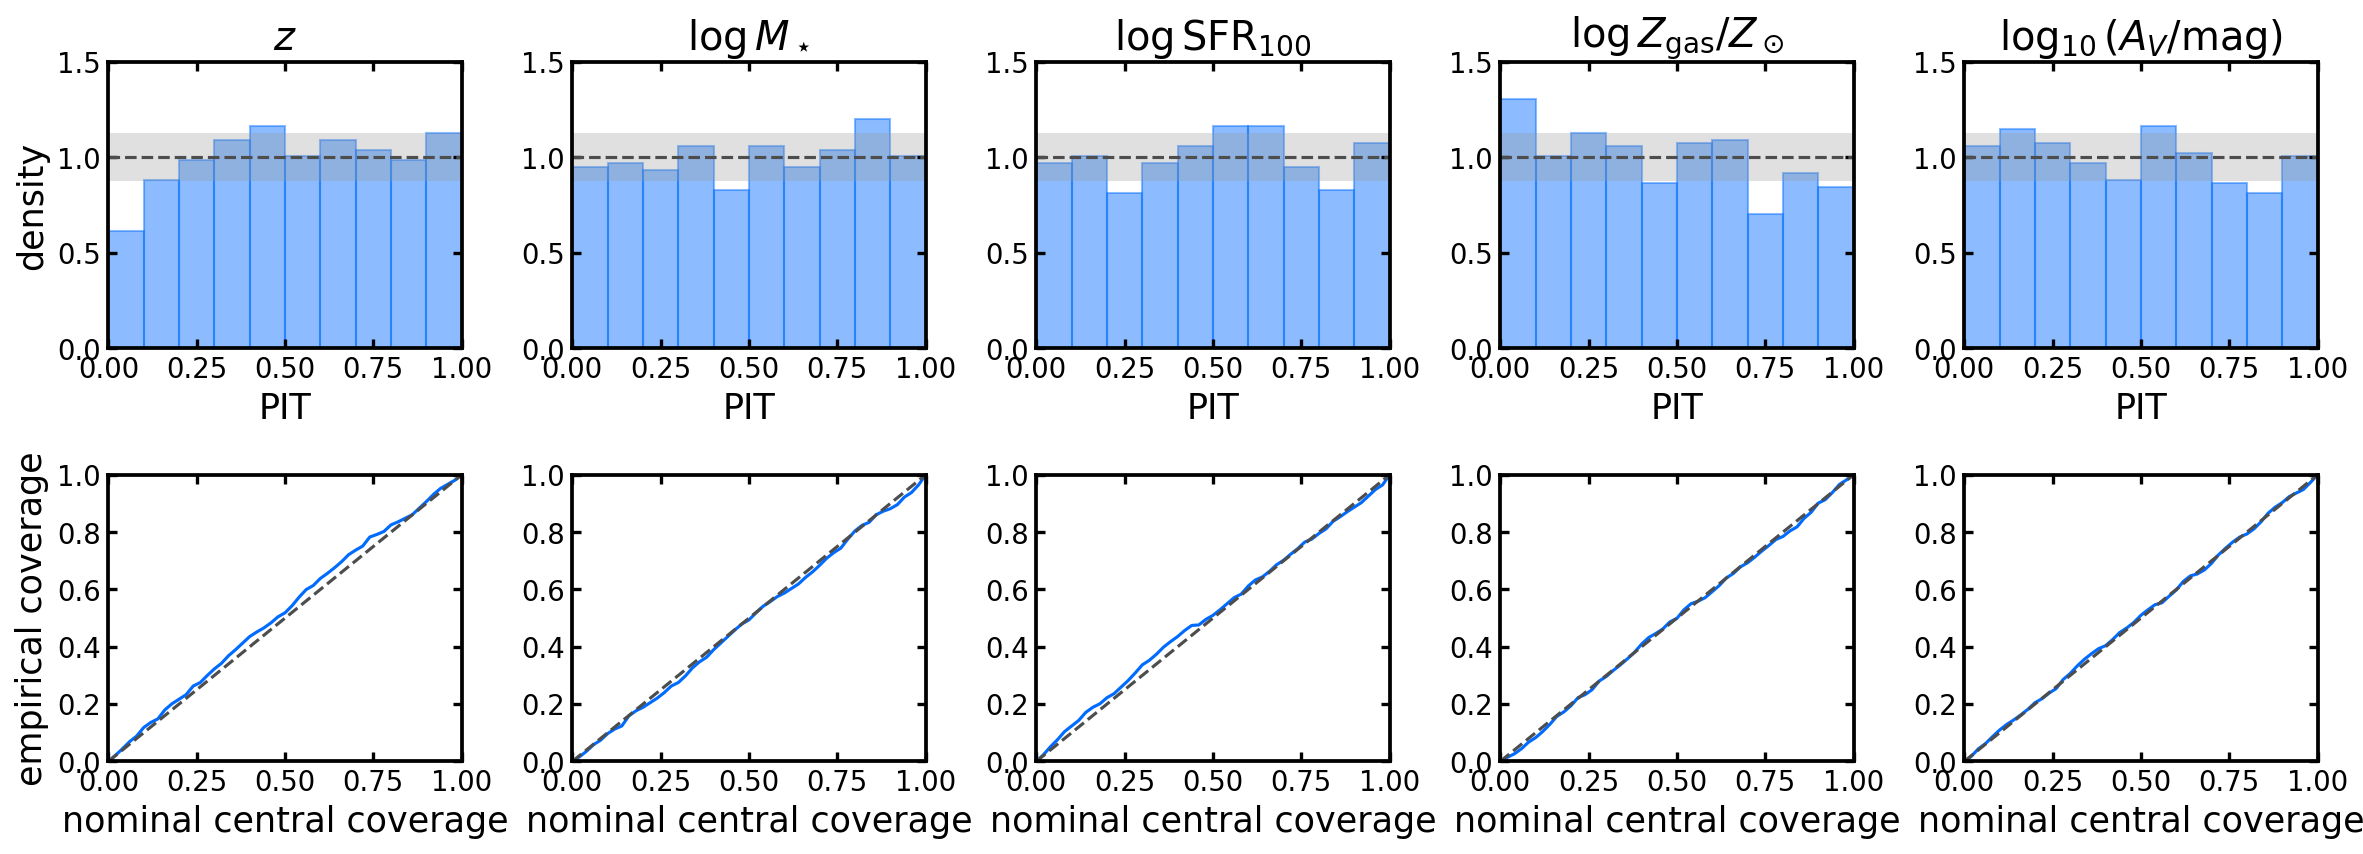

In [43]:
from scipy import stats
from scipy.special import polygamma

pit = (post < yt[None]).mean(axis=0)
N, nb = len(te), 10
S = post.shape[0]
# Beta likelihood is undefined at exactly 0 or 1; move those PITs half a sample inside.
pit_fit = np.clip(pit, 0.5 / S, 1 - 0.5 / S)
levels = np.linspace(0, 1, 51)
coverage = np.array([(np.abs(pit - 0.5) <= level / 2).mean(axis=0) for level in levels])
xg = np.linspace(0.002, 0.998, 400)


def fit_beta(u):
    """Beta MLE on (0, 1) with 1-sigma errors from the inverse Fisher information."""
    a, b, _, _ = stats.beta.fit(u, floc=0, fscale=1)
    t = polygamma(1, a + b)
    fisher = np.array([[polygamma(1, a) - t, -t], [-t, polygamma(1, b) - t]])
    sa, sb = np.sqrt(np.diag(np.linalg.inv(len(u) * fisher)))
    return a, b, sa, sb


beta_fits = {}
fig, axes = plt.subplots(2, D, figsize=(3.2 * D, 6), squeeze=False)
band = np.sqrt((nb - 1) / N)
for d in range(D):
    a, b, sa, sb = beta_fits[names[d]] = fit_beta(pit_fit[:, d])
    ax = axes[0, d]
    ax.hist(pit[:, d], bins=nb, range=(0, 1), density=True,
            color=C_IMAGE, alpha=0.45, edgecolor=C_IMAGE)
    ax.axhspan(max(0, 1 - band), 1 + band, color="0.6", alpha=0.3, lw=0)
    ax.axhline(1, color="0.3", ls="--")
    ax.plot(xg, stats.beta.pdf(xg, a, b), color=C_RED_BRIGHT, lw=1.5)
    ax.text(0.5, 0.97, rf"$\alpha$={a:.2f}$\pm${sa:.2f}" + "\n" + rf"$\beta$={b:.2f}$\pm${sb:.2f}",
            transform=ax.transAxes, ha="center", va="top", fontsize=fs(8))
    ax.set(xlabel="PIT", title=LABELS[d], xlim=(0, 1))
    ax.set_ylim(0, 1.5)
    ax = axes[1, d]
    ax.plot(levels, coverage[:, d], color=C_IMAGE)
    ax.plot([0, 1], [0, 1], "--", color="0.3")
    ax.set(xlabel="nominal central coverage", xlim=(0, 1), ylim=(0, 1))
    for ax in axes[:, d]:
        style_axes(ax)
    cov68, cov95 = [(np.abs(pit[:, d] - 0.5) <= L / 2).mean() for L in (0.68, 0.95)]
    print(f"{names[d]:12s} cov68={cov68:.3f}  cov95={cov95:.3f}  "
          f"alpha={a:.3f}+-{sa:.3f}  beta={b:.3f}+-{sb:.3f}")
axes[0, 0].set_ylabel("density")
axes[1, 0].set_ylabel("empirical coverage")
fig.tight_layout()
plt.show()